In [1]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install pillow

Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.


In [4]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt
from IPython.display import HTML

from tensorflow.keras.preprocessing.image import ImageDataGenerator

2026-01-14 16:49:54.182440: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-01-14 16:49:54.184037: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-01-14 16:49:54.206596: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-01-14 16:49:54.206621: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-01-14 16:49:54.207376: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to

In [5]:
print(tf.__version__)

2.15.0


In [6]:
IMAGE_SIZE = 256
CHANNELS = 3

train_datagen = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True,
    rotation_range=10
)

train_generator = train_datagen.flow_from_directory(
    'dataset/train',
    target_size = (IMAGE_SIZE, IMAGE_SIZE),
    batch_size=32,
    class_mode='sparse'
)

Found 1506 images belonging to 3 classes.


In [7]:
train_generator.class_indices

{'Potato___Early_blight': 0, 'Potato___Late_blight': 1, 'Potato___healthy': 2}

In [8]:
class_names = list(train_generator.class_indices.keys())
class_names

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

In [9]:
validation_datagen = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True,
    rotation_range=10
)

validation_generator = validation_datagen.flow_from_directory(
    'dataset/val',
    target_size = (IMAGE_SIZE, IMAGE_SIZE),
    batch_size=32,
    class_mode='sparse'
)

Found 215 images belonging to 3 classes.


In [10]:
test_datagen = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True,
    rotation_range=10
)

test_generator = test_datagen.flow_from_directory(
    'dataset/test',
    target_size = (IMAGE_SIZE, IMAGE_SIZE),
    batch_size=32,
    class_mode='sparse'
)

Found 431 images belonging to 3 classes.


In [11]:
input_shape = (IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
n_classes = 3

model = models.Sequential([
    layers.InputLayer(input_shape=input_shape),
    layers.Conv2D(32, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(n_classes, activation='softmax'),
    
])

In [12]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 254, 254, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 127, 127, 32)      0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 125, 125, 64)      18496     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 62, 62, 64)        0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 60, 60, 64)        36928     
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 30, 30, 64)        0

In [13]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

In [14]:
1506//32

47

In [15]:
history = model.fit(
    train_generator,
    steps_per_epoch=47, 
    batch_size=32,
    validation_data = validation_generator,
    validation_steps=6,
    verbose=1,
    epochs=20
)

Epoch 1/20
47/47 [==============================] - 29s 605ms/step - loss: 0.9235 - accuracy: 0.4654 - val_loss: 0.8684 - val_accuracy: 0.4688
Epoch 2/20
47/47 [==============================] - 29s 629ms/step - loss: 0.8149 - accuracy: 0.5801 - val_loss: 0.8625 - val_accuracy: 0.5990
Epoch 3/20
47/47 [==============================] - 28s 594ms/step - loss: 0.5978 - accuracy: 0.7524 - val_loss: 0.4696 - val_accuracy: 0.8021
Epoch 4/20
47/47 [==============================] - 27s 580ms/step - loss: 0.4162 - accuracy: 0.8311 - val_loss: 0.4124 - val_accuracy: 0.8646
Epoch 5/20
47/47 [==============================] - 36s 764ms/step - loss: 0.3114 - accuracy: 0.8826 - val_loss: 0.2752 - val_accuracy: 0.8854
Epoch 6/20
47/47 [==============================] - 36s 765ms/step - loss: 0.3341 - accuracy: 0.8630 - val_loss: 0.3811 - val_accuracy: 0.8229
Epoch 7/20
47/47 [==============================] - 35s 751ms/step - loss: 0.3052 - accuracy: 0.8779 - val_loss: 0.3385 - val_accuracy: 0.8542

In [16]:
scores = model.evaluate(test_generator)

14/14 [==============================] - 5s 356ms/step - loss: 0.1935 - accuracy: 0.9234


In [17]:
scores

[0.19350336492061615, 0.9234338998794556]

In [18]:
history

In [19]:
history.params

{'verbose': 1, 'epochs': 20, 'steps': 47}

In [20]:
history.history.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

In [21]:
type(history.history['loss'])

list

In [22]:
len(history.history['loss'])

20

In [23]:
history.history['loss'][:5]

[0.9235107898712158,
 0.8148502111434937,
 0.5977680683135986,
 0.41622602939605713,
 0.3114435076713562]

In [24]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

In [25]:
val_acc

[0.46875,
 0.5989583134651184,
 0.8020833134651184,
 0.8645833134651184,
 0.8854166865348816,
 0.8229166865348816,
 0.8541666865348816,
 0.8645833134651184,
 0.9166666865348816,
 0.890625,
 0.921875,
 0.9010416865348816,
 0.9375,
 0.9114583134651184,
 0.9739583134651184,
 0.9427083134651184,
 0.9375,
 0.9479166865348816,
 0.96875,
 0.953125]

In [26]:
acc

[0.4654002785682678,
 0.5800542831420898,
 0.7523744702339172,
 0.8310719132423401,
 0.882632315158844,
 0.8629579544067383,
 0.8778833150863647,
 0.9070556163787842,
 0.9168882966041565,
 0.9199457168579102,
 0.9192672967910767,
 0.9436906576156616,
 0.9355053305625916,
 0.9416553378105164,
 0.9423337578773499,
 0.9538670182228088,
 0.9762550592422485,
 0.9633650183677673,
 0.9748982191085815,
 0.9518317580223083]

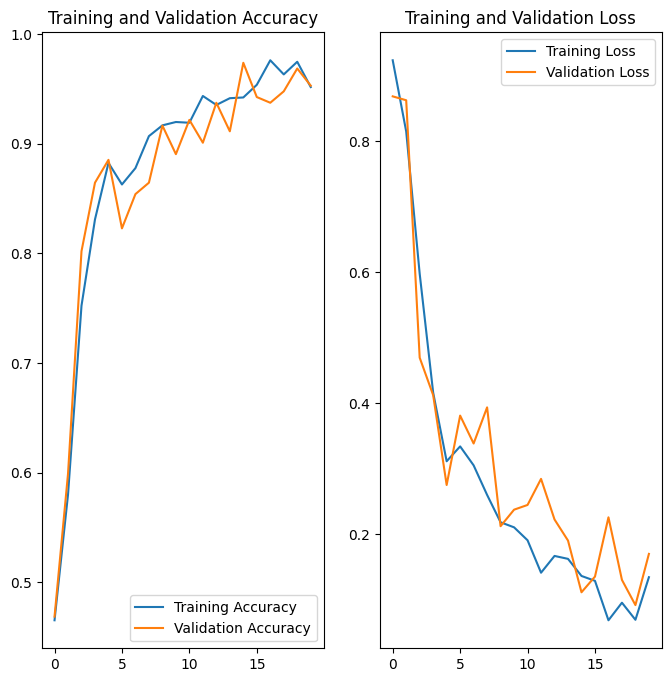

In [27]:
EPOCHS = 20

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(range(EPOCHS), acc, label='Training Accuracy')
plt.plot(range(EPOCHS), val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(range(EPOCHS), loss, label='Training Loss')
plt.plot(range(EPOCHS), val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

first image to predict
actual label:  Potato___Late_blight
1/1 [==============================] - 0s 233ms/step
predicted label: Potato___Late_blight


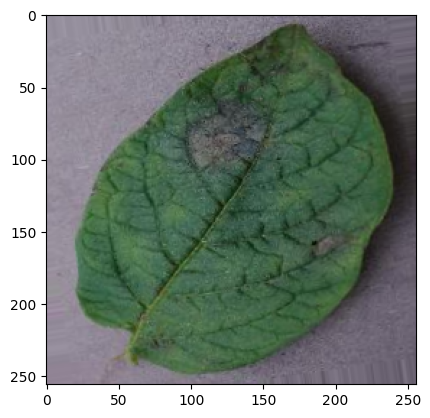

In [28]:
import numpy as np

for image_batch, label_batch in test_generator:
    first_image = image_batch[0]
    first_label = int(label_batch[0])

    print("first image to predict")
    plt.imshow(first_image)
    print("actual label: ", class_names[first_label])

    batch_prediction = model.predict(image_batch)
    print("predicted label:", class_names[np.argmax(batch_prediction[0])])

    break
    

In [29]:
def predict(model, img):
    img_array = tf.keras.preprocessing.image.img_to_array(images[i])
    img_array = tf.expand_dims(img_array, 0)

    predictions = model.predict(img_array)

    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = round(100 * (np.max(predictions[0])), 2)
    return predicted_class, confidence

1/1 [==============================] - 0s 20ms/step


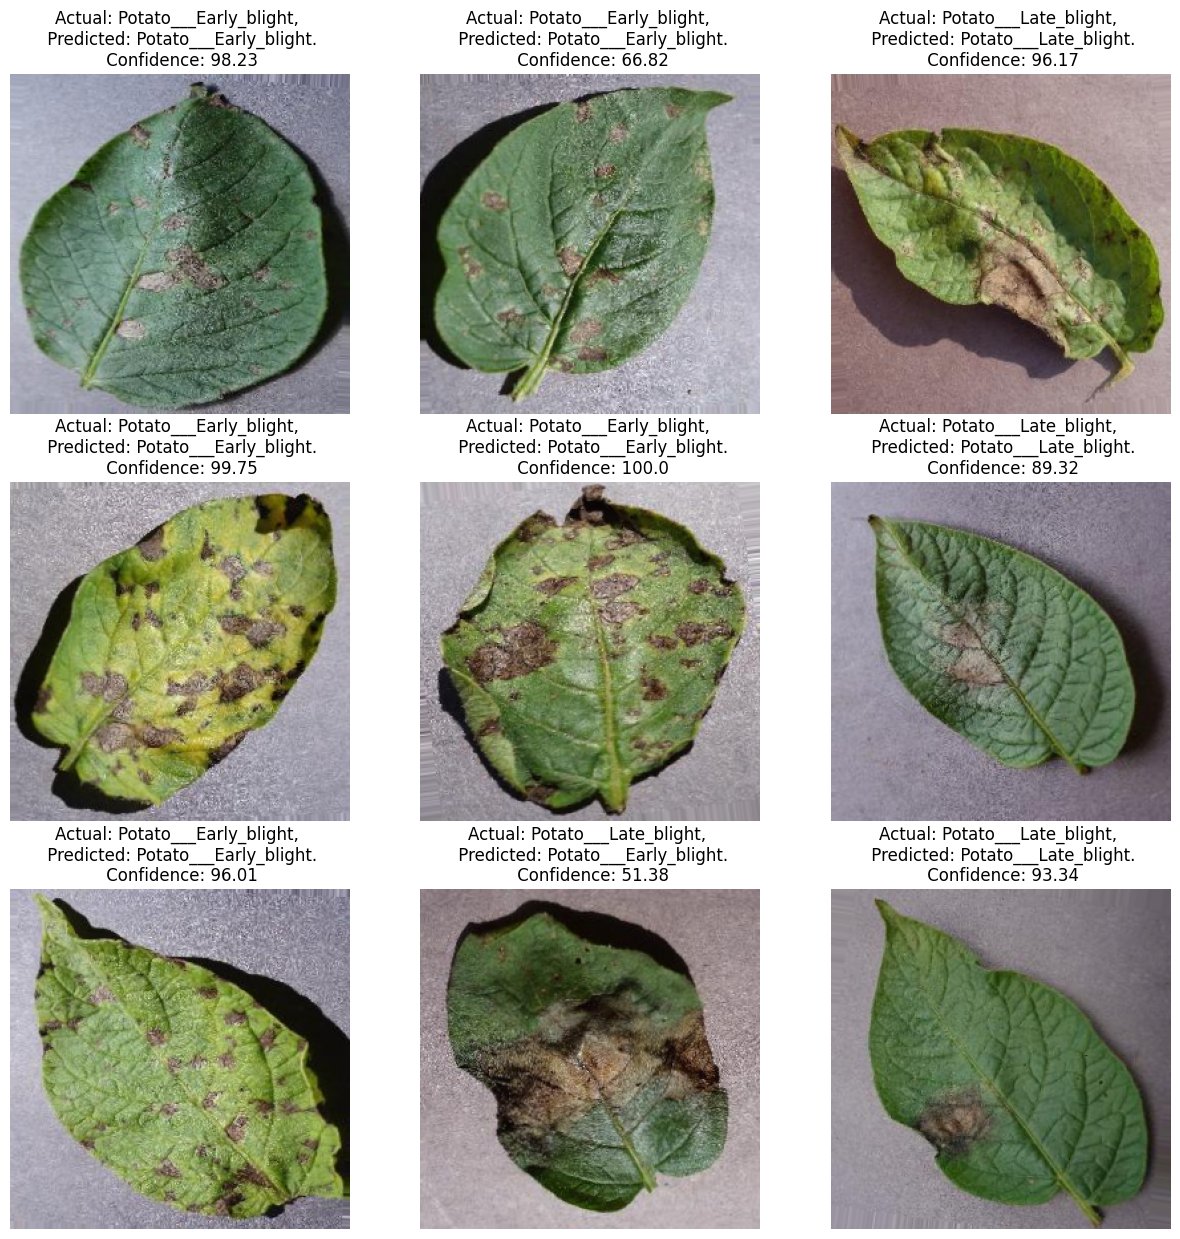

In [30]:
plt.figure(figsize=(15, 15))
for images, labels in test_generator:
    for i in range(9):
        ax = plt.subplot(3, 3, i+1)
        plt.imshow(images[i])

        predicted_class, confidence = predict(model, images[i])
        actual_class = class_names[int(labels[i])]
        plt.title(f"Actual: {actual_class}, \n Predicted: {predicted_class}.\n Confidence: {confidence}")
        plt.axis("off")
    break

In [33]:

model.save("../potatoes_cloud", save_format="tf")

INFO:tensorflow:Assets written to: ../potatoes_cloud/assets


INFO:tensorflow:Assets written to: ../potatoes_cloud/assets


In [34]:
print(tf.__version__)

2.15.0
